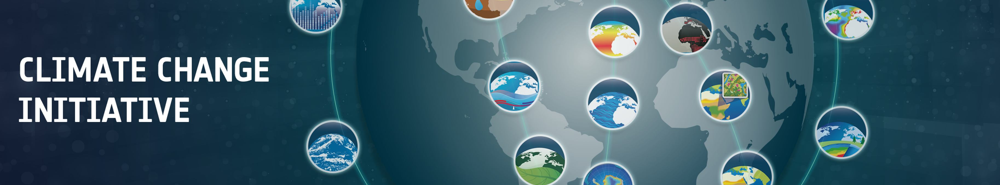

# Getting Started with High Resolution Land Cover CCI Data

### 1. Import Necessary Packages

In this section, we import the required Python packages to work with ESA Climate Change Initiative (CCI) data. Most notably, we use the [ESA Climate Toolbox](https://esa-climate-toolbox.readthedocs.io/en/latest/) which simplifies access, manipulation, and visualization of CCI datasets in Python.

These packages allow us to:
- Access satellite-based climate data records from ESA.
- Handle geospatial and temporal dimensions efficiently.
- Visualize data with intuitive plotting tools.

📚 For a broader introduction to the toolbox and how to install it, visit:  
🔗 [ESA CCI Climate Toolbox Quick Start](https://esa-climate-toolbox.readthedocs.io/en/latest/quick_start.html#jupyter-notebooks)  
🔗 [ESA Climate Data Toolbox Website](https://climate.esa.int/en/data/toolbox/)

In [1]:
from xcube.core.store import new_data_store
from esa_climate_toolbox.core import get_op
from esa_climate_toolbox.core import list_ecv_datasets
from esa_climate_toolbox.core import get_store
from esa_climate_toolbox.core import list_datasets
from esa_climate_toolbox.ops import plot
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
import cartopy.crs as ccrs
import warnings
warnings.filterwarnings("ignore") # Suppressing warnings to keep notebook output clean
%matplotlib inline

### Step 2: Connect to the ESA CCI Data Store

The ESA Climate Toolbox provides direct access to the **ESA Climate Data Store**, which hosts harmonized satellite-based climate data records produced under the **ESA Climate Change Initiative (CCI)**.

In this step, we establish a connection to the data store so we can browse and open datasets. This connection allows us to access data **without having to download files manually** — a convenient way to explore and analyze large geospatial datasets in cloud-friendly formats such as **Zarr** or **Kerchunk**.

The data store includes a wide range of essential climate variables (ECVs), such as aerosols, land surface temperature, sea level, and soil moisture. We can list all High Resolution Land Cover datasets with the `list_ecv_datasets("LC")` command, where LC is the abbreviation for Land Cover. 

📘 Learn more about available datasets:  
🔗 [ESA Climate Data Toolbox – Quick Start Guide](https://esa-climate-toolbox.readthedocs.io/en/latest/quick_start.html#data-access)

In [2]:
cci_store = new_data_store("esa-cci")
# List all available data sets of an ECV
list_ecv_datasets("LC")

[('esacci.LC.13-yrs.L4.WB.ASAR.Envisat.Map.4-0.r1', 'esa-cci'),
 ('esacci.LC.yr.L4.LCCS.multi-sensor.multi-platform.Map.2-0-7.r1', 'esa-cci'),
 ('esacci.LC.yr.L4.PFT.Unspecified.Unspecified.Map.2-0-81.r1', 'esa-cci'),
 ('esacci.LC.5-yrs.L4.CHANGE.multi-sensor.multi-platform.HRLCC30-A01.v1-2.Africa',
  'esa-cci'),
 ('esacci.LC.5-yrs.L4.CHANGE.multi-sensor.multi-platform.HRLCC30-A02.v1-2.Amazonia',
  'esa-cci'),
 ('esacci.LC.5-yrs.L4.CHANGE.multi-sensor.multi-platform.HRLCC30-A03.v1-2.Siberia',
  'esa-cci'),
 ('esacci.LC.5-yrs.L4.Map.multi-sensor.multi-platform.HRLC30-A01.v1-2.Africa',
  'esa-cci'),
 ('esacci.LC.5-yrs.L4.Map.multi-sensor.multi-platform.HRLC30-A02.v1-2.Amazonia',
  'esa-cci'),
 ('esacci.LC.5-yrs.L4.Map.multi-sensor.multi-platform.HRLC30-A03.v1-2.Siberia',
  'esa-cci'),
 ('esacci.LC.yr.L4.Map.multi-sensor.multi-platform.HRLC10-A01.v1-2.Africa',
  'esa-cci'),
 ('esacci.LC.yr.L4.Map.multi-sensor.multi-platform.HRLC10-A02.v1-2.Amazonia',
  'esa-cci'),
 ('esacci.LC.yr.L4.Map.m

There are some data IDs which have the abbreviation `HRLC` in their name which means high resolution land cover. These datasets provide a particularly high resolution of either 10 metres (HRLC10) or 30 metres (HRLC30). For more details, see [https://climate.esa.int/de/projekte/high-resolution-land-cover/](https://climate.esa.int/de/projekte/high-resolution-land-cover/)) For this notebook, we pick one of the datasets with 30 m resolution.

### Step 3: Define the Dataset ID  
To work with a specific ESA CCI dataset, we need to specify its **dataset ID**. This unique identifier tells the toolbox which variable and product we want to access.

In this example, we are using a dataset from the [**High Resolution Land Cover CCI project**](https://climate.esa.int/en/projects/high-resolution-land-cover/) that provides datasets for three regions in the Amazon, Africa and Siberia. You can find more details and a product description in the [Product User Guide](https://climate.esa.int/media/documents/CCI_HRLC_Ph1-D4.3_PUG_v2.2.pdf). 

We will use the following dataset ID:

In [29]:
data_id = "esacci.LC.yr.L4.Map.multi-sensor.multi-platform.HRLC10-A01.v1-2.Africa"

### Step 4: Describe Dataset (Check Available Variables and Metadata)

Before loading the full dataset, it’s helpful to **inspect the metadata** to understand its structure. This includes:

- Available variables (e.g., lccs_class, uncertainty estimates)
- Temporal and spatial coverage
- Data format and structure

This step ensures we know what the dataset contains and how to work with it. It also helps confirm that the variable we want to plot or analyse is actually included.

🛠️ Tip: You can use the description to verify variable names, dimensions (e.g., `lat`, `lon`, `time`), and time coverage.

📘 More on dataset structure:  
🔗 [ESA Climate Toolbox – Data Access](https://esa-climate-toolbox.readthedocs.io/en/latest/quick_start.html#accessing-data)

In [4]:
cci_store.describe_data(data_id)

### Step 5: Check Open Parameters for the Dataset

We can see in the step above, that the data_type is `datatree`. Under data_nodes we see a lot of letter-number combinations, in the next step we will have a look at what they mean. 

To open the dataset, we use the xcube store framework to open the `esa-cci` store. We can then display the parameters for opening the data. In many cases, this is not necessary, here it makes sense, as it allows us to see which places are available for this dataset.
The command below lists all expected input parameters and their allowed values for the selected dataset.

In [5]:
cci_store.get_open_data_params_schema(data_id=data_id, opener_id='dataset:zarr:cciodp')

Under `place_names`, we see the same letter and number combinations as above, you can find them if you look at `root->properties-> place_names->items->enum`. There you get a long list of the place names. These place names can be used to specify the regions you are interested in. This helps with managing this dataset, which otherwise would be very huge and hard to handle. The place names are given as tiles, and the tiling is based on the Sentinel-2 Tiling Grid, which you may download here: [https://sentiwiki.copernicus.eu/web/s2-products](https://sentiwiki.copernicus.eu/web/s2-products). Each tile covers 100x100 km. For this notebook, we pick tile "A01T33PVQ", while the A01 declares which area code we are using. The tile names are structured as follows:

Area code A01 = Africa, A02 = Amazon, A03 = Siberia (3 chars) concatenated with the tile code following Sentinel-2 tiling system based on MGRS (6 chars). The tile name is separated from the area code with the letter "T". 

Tip: You can search for the desired tile on this website: [https://dpird-dma.github.io/Sentinel-2-grid-explorer/](https://dpird-dma.github.io/Sentinel-2-grid-explorer/)

In [16]:
places = ["A01T33PVQ"]

### Step 6: Open the Datatree

Now we open the dataset using the selected tile / place as defined above.
The ESA Climate Toolbox will download only the necessary data (e.g., variable and time range).
You can always adjust the time range or variables to explore different slices of the dataset.

In [30]:
hrlc_dt = cci_store.open_data(
    data_id,
    place_names=places
)
hrlc_dt

<xarray.DataTree 'esacci.LC.yr.L4.Map.multi-sensor.multi-platform.HRLC10-A01.v1-2.Africa'>
Group: /
└── Group: /
        Dimensions:    (time: 1, y: 10980, x: 10980, bnds: 2)
        Coordinates:
          * time       (time) datetime64[ns] 8B 2019-07-02T12:00:00
          * y          (y) float64 88kB 1.5e+06 1.5e+06 1.5e+06 ... 1.39e+06 1.39e+06
          * x          (x) float64 88kB 4e+05 4e+05 4e+05 ... 5.097e+05 5.098e+05
            time_bnds  (time, bnds) datetime64[ns] 16B dask.array<chunksize=(1, 2), meta=np.ndarray>
        Dimensions without coordinates: bnds
        Data variables:
            CL01       (time, y, x) uint8 121MB dask.array<chunksize=(1, 1830, 1830), meta=np.ndarray>
            CL02       (time, y, x) uint8 121MB dask.array<chunksize=(1, 1830, 1830), meta=np.ndarray>
            IQIX       (time, y, x) uint8 121MB dask.array<chunksize=(1, 1830, 1830), meta=np.ndarray>
            PS01       (time, y, x) uint8 121MB dask.array<chunksize=(1, 1830, 1830), met

We can make sure the place is included in the list of keys of the DataTree like this:

In [18]:
list(hrlc_dt.keys())

['A01T33PVQ']

### Step 7: Get the Dataset and Change the Projection
Now we can retrieve the region-specific dataset from the data tree as follows:

In [19]:
hrlc_ds = hrlc_dt.get(places[0]).to_dataset()
hrlc_ds

<xarray.Dataset> Size: 603MB
Dimensions:    (time: 1, y: 10980, x: 10980, bnds: 2)
Coordinates:
  * time       (time) datetime64[ns] 8B 2019-07-02T12:00:00
  * y          (y) float64 88kB 1.5e+06 1.5e+06 1.5e+06 ... 1.39e+06 1.39e+06
  * x          (x) float64 88kB 4e+05 4e+05 4e+05 ... 5.097e+05 5.098e+05
    time_bnds  (time, bnds) datetime64[ns] 16B dask.array<chunksize=(1, 2), meta=np.ndarray>
Dimensions without coordinates: bnds
Data variables:
    CL01       (time, y, x) uint8 121MB dask.array<chunksize=(1, 1830, 1830), meta=np.ndarray>
    CL02       (time, y, x) uint8 121MB dask.array<chunksize=(1, 1830, 1830), meta=np.ndarray>
    IQIX       (time, y, x) uint8 121MB dask.array<chunksize=(1, 1830, 1830), meta=np.ndarray>
    PS01       (time, y, x) uint8 121MB dask.array<chunksize=(1, 1830, 1830), meta=np.ndarray>
    PS02       (time, y, x) uint8 121MB dask.array<chunksize=(1, 1830, 1830), meta=np.ndarray>
Attributes:
    Conventions:             CF-1.7
    title:                   esacci.LC.yr.L4.Map.multi-sensor.multi-platform....
    date_created:            2026-11-06T08:14:09.495741
    processing_level:        L4
    time_coverage_start:     2019-01-01T00:00:00
    time_coverage_end:       2020-01-01T00:00:00
    time_coverage_duration:  P365DT0H0M0S
    history:                 [{'program': 'xcube_cci.chunkstore.CciChunkStore...

One thing to notice here is that this dataset does not have latitude and longitude coordinates. This is because the data is provided in a UTM projection. We can work with this as is, but some may prefer to work in WGS 84, so we show you how to reproject to that. The following is based on the [`🔗Reprojecting_Data`](https://github.com/esa-cci/esa-climate-toolbox/blob/main/notebooks/Using_Operations/3-ECT_Reprojecting_Data.ipynb) notebook in the [`🔗Using_Operations`](https://github.com/esa-cci/esa-climate-toolbox/tree/main/notebooks/Using_Operations) section. We start by determining the grid mapping of the dataset.
You can also find more information on any operation in the [Documentation of the Toolbox](https://esa-climate-toolbox.readthedocs.io/en/latest/api_reference.html#operations).

In [20]:
from xcube.core.gridmapping import GridMapping

source_gm = GridMapping.from_dataset(hrlc_ds)
source_gm

class: **RegularGridMapping**
* is_regular: True
* is_j_axis_up: False
* is_lon_360: _unknown_
* crs: PROJCS["WGS 84 / UTM zone 33N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",15],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32633"]]
* xy_res: (10, 10)
* xy_bbox: (399960, 1390200, 509760, 1500000)
* ij_bbox: (0, 0, 10980, 10980)
* xy_dim_names: ('x', 'y')
* xy_var_names: ('x', 'y')
* size: (10980, 10980)
* tile_size: (1830, 1830)

As we can see from the Coordinate Reference Systems (crs) in the list, the dataset is given as Universal Transverse Mercator (UTM) projection. We will transform the `source_gm` to our desired target crs, which is WGS84, in the next step. The input is given via EPSG Geodetic Parameter Dataset with EPSG:4326. 

In [21]:
target_gm = source_gm.transform("EPSG:4326")
target_gm

class: **Coords2DGridMapping**
* is_regular: dask.array<all-aggregate, shape=(), dtype=bool, chunksize=(), chunktype=numpy.ndarray>
* is_j_axis_up: dask.array<all-aggregate, shape=(), dtype=bool, chunksize=(), chunktype=numpy.ndarray>
* is_lon_360: False
* crs: EPSG:4326
* xy_res: (9.241784050573187e-05, 9.041130688203225e-05)
* xy_bbox: (14.07536678103501, 12.57398396376946, 15.090212227898496, 13.568451272547444)
* ij_bbox: (0, 0, 10980, 10980)
* xy_dim_names: ('x', 'y')
* xy_var_names: ('transformed_x', 'transformed_y')
* size: (10980, 10980)
* tile_size: (1830, 1830)

Now we can use the operator `resample_in_space` from the toolbox to apply the transformed projection. 

In [22]:
from xcube.core.resampling import resample_in_space

hrlc_ds = resample_in_space(
    hrlc_ds,
    source_gm=source_gm,
    target_gm=target_gm,
)
hrlc_ds

<xarray.Dataset> Size: 603MB
Dimensions:        (time: 1, y: 10980, x: 10980, bnds: 2)
Coordinates:
  * time           (time) datetime64[ns] 8B 2019-07-02T12:00:00
    transformed_y  (y) float64 88kB 13.57 13.57 13.57 ... 12.57 12.57 12.57
    transformed_x  (x) float64 88kB 14.08 14.08 14.08 ... 15.09 15.09 15.09
    time_bnds      (time, bnds) datetime64[ns] 16B dask.array<chunksize=(1, 2), meta=np.ndarray>
    spatial_ref    int64 8B 0
Dimensions without coordinates: y, x, bnds
Data variables:
    CL01           (time, y, x) uint8 121MB dask.array<chunksize=(1, 1830, 1830), meta=np.ndarray>
    CL02           (time, y, x) uint8 121MB dask.array<chunksize=(1, 1830, 1830), meta=np.ndarray>
    IQIX           (time, y, x) uint8 121MB dask.array<chunksize=(1, 1830, 1830), meta=np.ndarray>
    PS01           (time, y, x) uint8 121MB dask.array<chunksize=(1, 1830, 1830), meta=np.ndarray>
    PS02           (time, y, x) uint8 121MB dask.array<chunksize=(1, 1830, 1830), meta=np.ndarray>
    crs            int64 8B 0
Attributes:
    Conventions:             CF-1.7
    title:                   esacci.LC.yr.L4.Map.multi-sensor.multi-platform....
    date_created:            2026-11-06T08:14:09.495741
    processing_level:        L4
    time_coverage_start:     2019-01-01T00:00:00
    time_coverage_end:       2020-01-01T00:00:00
    time_coverage_duration:  P365DT0H0M0S
    history:                 [{'program': 'xcube_cci.chunkstore.CciChunkStore...

As we can see in the dataset above, the reprojection worked. For more convenience we can rename the transformed_x and transformed_y to lat and lon. 

In [23]:
hrlc_ds = hrlc_ds.rename({"x": "lon", "y": "lat", "transformed_x": "lon", "transformed_y": "lat"})
# hrlc_ds

### Step 8: Visualise Results
Now let's have a look at the data. We will look at the Classification product (CL01) (see [Product User Guide](https://climate.esa.int/media/documents/CCI_HRLC_Ph1-D4.3_PUG_v2.2.pdf)). The data is given as categorical data and we can conveniently use the toolbox' `plot_categorical` operation. It even has implemented colour maps for the land cover classification. You can find the color_scheme_names in the [toolbox documentation](https://esa-climate-toolbox.readthedocs.io/en/latest/api_reference.html#esa_climate_toolbox.ops.plot_categorical).

In [24]:
from esa_climate_toolbox.core import get_op

plot_categorical = get_op("plot_categorical")

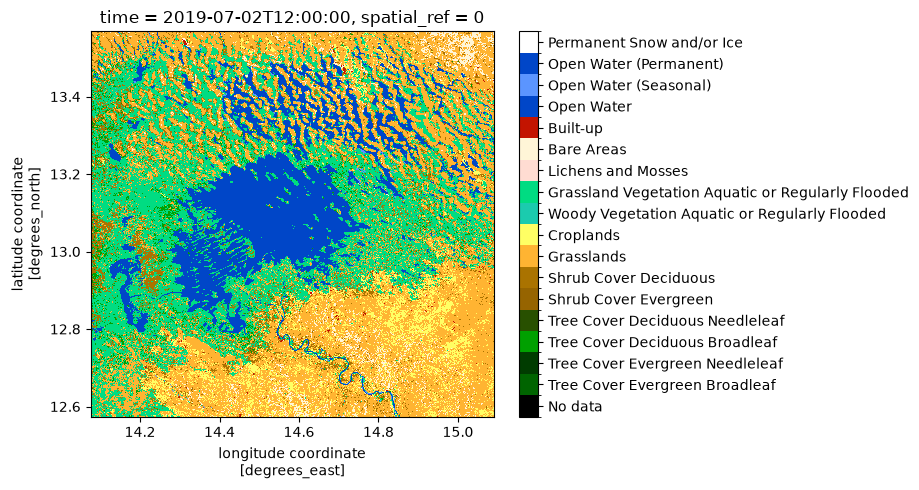

In [25]:
plot_categorical(hrlc_ds, "CL01", 
                 indexers={"time": hrlc_ds.time[0].values}, 
                 color_scheme_name="highres_land_cover_cci", 
                 properties=dict(figsize=(9, 5))
                )